MODULARITY STUDY ON KARATE CLUB GRAPH

DSC-212:GRAPH THEORY

OBJECTIVE: 
- Implement recursive spectral modularity partitioning to detect multiple communities in the Karate Club graph  
- Visualize the graph after each split with different colors for communities  
- Compute node metrics (degree centrality, betweenness centrality, closeness centrality, clustering)  
- Plot how these metrics evolve across iterations  
- Write a short discussion about which nodes remain central and how community structure influences metrics 

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
G = nx.karate_club_graph()
print("nodes:",G.number_of_nodes())
print("edges:",G.number_of_edges())

nodes: 34
edges: 78


Here numpy and matplotlib are the libraries i use to do this problem. The networkx library is imported to work on the built in karate club graph with the nodes and edges number as shown above.


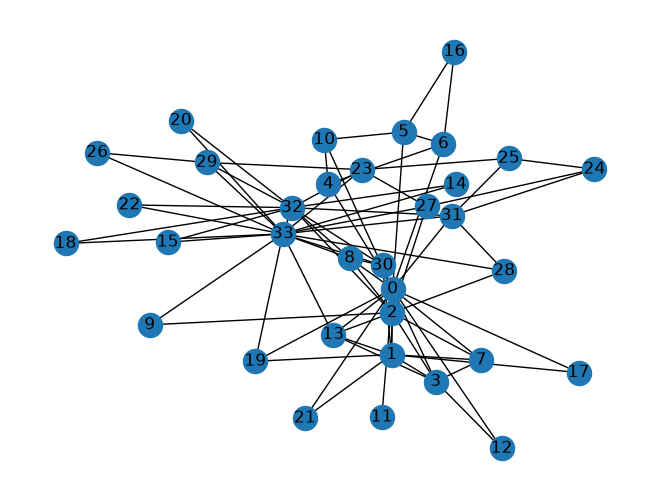

In [3]:
nx.draw(G, with_labels=True)
plt.show()

The visual representation of the karate club graph from networkx is shown.


ADJACENCY MATRIX:
This is a square matrix of dimension n by n that consists of information on whether two vertices are connected. Here we use 1 to represent a connection and 0 to represent no-connection

In [4]:
A=nx.to_numpy_array(G)

print(A)

[[0. 4. 5. ... 2. 0. 0.]
 [4. 0. 6. ... 0. 0. 0.]
 [5. 6. 0. ... 0. 2. 0.]
 ...
 [2. 0. 0. ... 0. 4. 4.]
 [0. 0. 2. ... 4. 0. 5.]
 [0. 0. 0. ... 4. 5. 0.]]


The numbers other than 0 and 1 is given because in the original graph they use weighted edges. 

In [5]:
A = nx.to_numpy_array(G,weight=None, dtype=int)

print(A)

[[0 1 1 ... 1 0 0]
 [1 0 1 ... 0 0 0]
 [1 1 0 ... 0 1 0]
 ...
 [1 0 0 ... 0 1 1]
 [0 0 1 ... 1 0 1]
 [0 0 0 ... 1 1 0]]


The weighted graph is converted to unweighted one with integer entries. Now we need to form the modularity matrix with the help of a null model.

In [6]:
k=np.sum(A, axis=1)
m=G.number_of_edges()
P=np.outer(k, k) / (2 * m)
B=A-P
print(B)

[[-1.64102564  0.07692308 -0.02564103 ...  0.38461538 -1.23076923
  -1.74358974]
 [ 0.07692308 -0.51923077  0.42307692 ... -0.34615385 -0.69230769
  -0.98076923]
 [-0.02564103  0.42307692 -0.64102564 ... -0.38461538  0.23076923
  -1.08974359]
 ...
 [ 0.38461538 -0.34615385 -0.38461538 ... -0.23076923  0.53846154
   0.34615385]
 [-1.23076923 -0.69230769  0.23076923 ...  0.53846154 -0.92307692
  -0.30769231]
 [-1.74358974 -0.98076923 -1.08974359 ...  0.34615385 -0.30769231
  -1.8525641 ]]


In the above code we created the modularity matrix with the help of degree matrix columns. The degree matrix columns multiplied with its transpose gave another n*n matrix which when divided by twice the number of edges gives the Null model that is used as our baseline. The null model preservesthe degree of each matrix where 2m represents total number of stubs in the graph.
Hence the probability of randomly pairing a stub from node i with one from node j is approximately: kj/2m
and each node i has ki stubs so expected number of connection between them is ki*kj/2m.
Hence P=ki*kj/2m
which when written in matrix gives: P=k*k_transpose/2m.



After this we calculate and try to maximise the modularity score:
The modularity Q of a particular division s is then given by Q = 1/4m(S_transpose*B*S)
A large positive value of Q indicates a meaningful split with significantly more within-community edges
than expected at random.




Spectral Partitioning Algorithm:
Here we move towards spectral partitioning with the help of s vector, where s ∈ {−1, +1}^n
is the community assignment vector. Here this poses a didifficulty cause checking for every value of s is not practical as for this particular example with n=34 it provide 2^34 possible assignments. So in roundabout way we instead of forcing si ∈ {−1, +1}, we allow s_i to take anyreal value, but constrain |s|2=1(squaring and adding all possible values of s then taking root over the sum). Using the Rayleigh–Ritz theorem we get the maximizer of max s_transpose*B*s  is the eigenvector of B corresponding to the largest eigenvalue, called the leading eigenvector.



In [7]:
#Calculation of eigenvalues and eigenvectors of B
eigenvalues, eigenvectors = np.linalg.eigh(B)
lambda_max = eigenvalues[-1]#largest eigen value
u1 = eigenvectors[:, -1]#eigenvector corresponding to largest eigen vector.
s=u1.real.copy()
i=0
while i < G.number_of_nodes():
    if u1.real[i] > 0:
        s[i] = 1
    else:
        s[i] = -1
    i = i + 1 #converting back to 1 and -1
community1 = np.where(s == 1)[0]
community2 = np.where(s == -1)[0]
Q = (s.T @ B @ s) / (4 * m)
print("Largest eigenvalue:", lambda_max)
print("Leading eigenvector:\n", u1)
print("\nCommunity 1:", community1)
print("Community 2:", community2)
print("\nModularity score:", Q)

Largest eigenvalue: 4.977080225729888
Leading eigenvector:
 [ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.05447571 -0.04785238  0.13400323  0.07784279
  0.12874396  0.13502861 -0.13943288 -0.13943288  0.05851821  0.13197981
 -0.13943288  0.05764888 -0.13943288  0.13197981 -0.13943288 -0.21674712
 -0.0563305  -0.07540039 -0.11580257 -0.10276487 -0.06834027 -0.20629456
 -0.09626391 -0.10185678 -0.32390453 -0.36983786]

Community 1: [ 0  1  2  3  4  5  6  7 10 11 12 13 16 17 19 21]
Community 2: [ 8  9 14 15 18 20 22 23 24 25 26 27 28 29 30 31 32 33]

Modularity score: 0.3714661406969099


Plot:


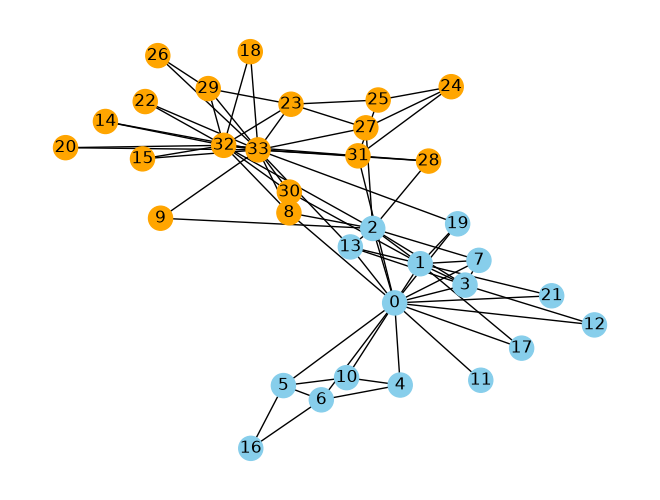

In [8]:
node_colors = []

for node in G.nodes():
    if node in community1:
        node_colors.append("skyblue")
    else:
        node_colors.append("orange")
nx.draw(G,node_color=node_colors, with_labels=True)

Now I have to go from two community to many. for that we have to use recursive bisection. This works on the principle that it goes through each community and take the nodes belonging to each community and contruct its modularity matrix B' after taking the subset on the original modularity matrix based on nodes. Now repeat the steps in spectral bipartitioning.


In [9]:
def recursive_bisection(B, nodes, communities):

    B_sub = B[np.ix_(nodes, nodes)]#uses subset of original matrix based on required nodes

    # Calculate eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(B_sub)

    # Find the largest eigenvalue
    lambda_max = eigenvalues[-1]

    print("Nodes:", nodes)
    print("Largest eigenvalue:", lambda_max)

    # Stopping condition
    if lambda_max <= 0:
        communities.append(nodes)
        print("Stopping: No further division\n")
        return

    # Get the leading eigenvector
    u1 = eigenvectors[:, -1]

    # Divide nodes according to eigenvector signs
    group1 = [nodes[i] for i in range(len(nodes)) if u1[i] > 0]
    group2 = [nodes[i] for i in range(len(nodes)) if u1[i] <= 0]

    if len(group1) == 0 or len(group2) == 0:
        communities.append(nodes)
        print("Stopping: Empty group produced\n")
        return

    print("Group 1:", group1)
    print("Group 2:", group2)
    print()

    recursive_bisection(B, group1, communities)
    recursive_bisection(B, group2, communities)
    # Start with all nodes
nodes = list(range(G.number_of_nodes()))
communities = []
recursive_bisection(B, nodes, communities)

print("\nFinal communities:")
for i, community in enumerate(communities):
    print(f"Community {i+1}: {community}")

Nodes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Largest eigenvalue: 4.977080225729888
Group 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Group 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]

Nodes: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Largest eigenvalue: 2.944128541023386
Group 1: [4, 5, 6, 10, 11, 16]
Group 2: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]

Nodes: [4, 5, 6, 10, 11, 16]
Largest eigenvalue: 2.1479926136897203
Group 1: [11]
Group 2: [4, 5, 6, 10, 16]

Nodes: [11]
Largest eigenvalue: -0.00641025641025641
Stopping: No further division

Nodes: [4, 5, 6, 10, 16]
Largest eigenvalue: 2.1470046881545466
Stopping: Empty group produced

Nodes: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Largest eigenvalue: 2.5711581746135295
Stopping: Empty group produced

Nodes: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Largest eigenvalue: 

The recursion stopping condition is given by the eigen value test:
Compute the leading eigenpair (λ)
if λ>0 then splitting is possible in the community and it increases modularity.
if λ<=0 then no further split improves modularity and C should remain as a single community.

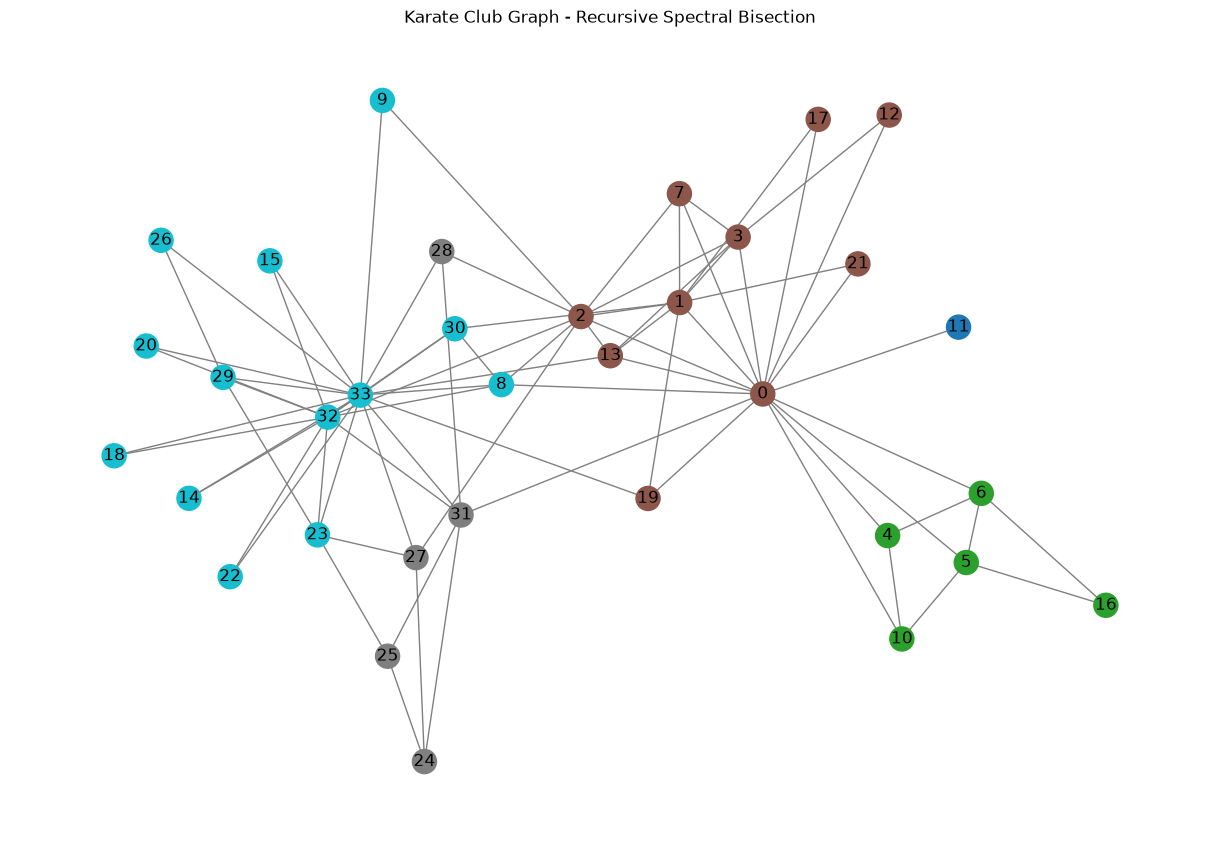

In [10]:

colors=plt.cm.tab10(np.linspace(0, 1, len(communities)))

node_colors={}
for i, community in enumerate(communities):
    for node in community:
        node_colors[node] = colors[i]

color_list=[node_colors[node] for node in G.nodes()]

plt.figure(figsize=(12, 8))

nx.draw(
    G,
    node_color=color_list,
    with_labels=True,
    edge_color="gray"
)

plt.title("Karate Club Graph - Recursive Spectral Bisection")
plt.show()

Plot of the graph after every partioning:


In [11]:
def collect_steps(B, nodes, communities, steps):

    B_sub = B[np.ix_(nodes, nodes)]
    eigenvalues, eigenvectors = np.linalg.eigh(B_sub)

    if eigenvalues[-1] <= 0:
        return

    u1 = eigenvectors[:, -1]

    group1 = [nodes[i] for i in range(len(nodes)) if u1[i] > 0]
    group2 = [nodes[i] for i in range(len(nodes)) if u1[i] <= 0]

    if not group1 or not group2:
        return

    communities.remove(nodes)
    communities.extend([group1, group2])

    steps.append([c.copy() for c in communities])

    collect_steps(B, group1, communities, steps)
    collect_steps(B, group2, communities, steps)


steps = []
initial_communities = [list(G.nodes())]

collect_steps(B, list(G.nodes()), initial_communities, steps)

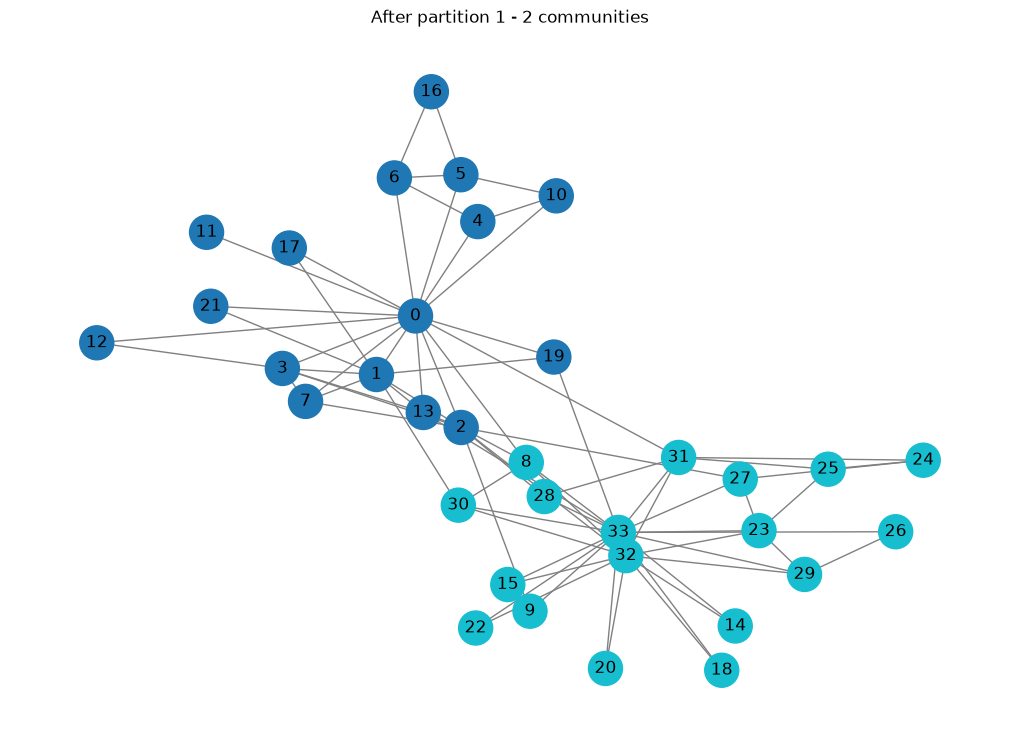

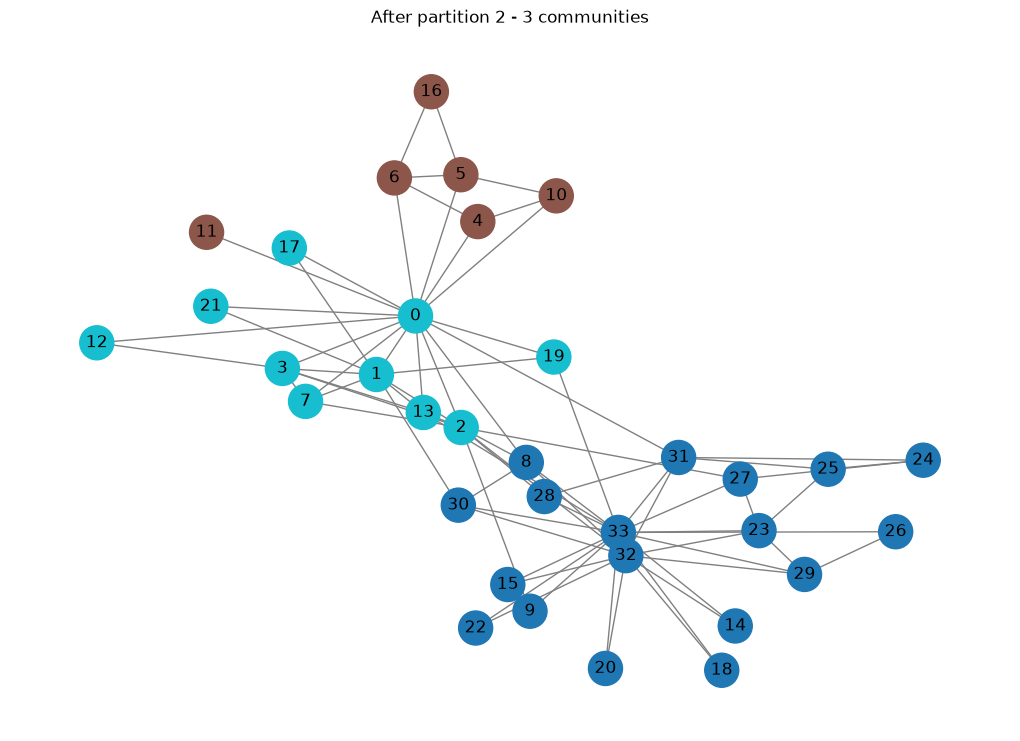

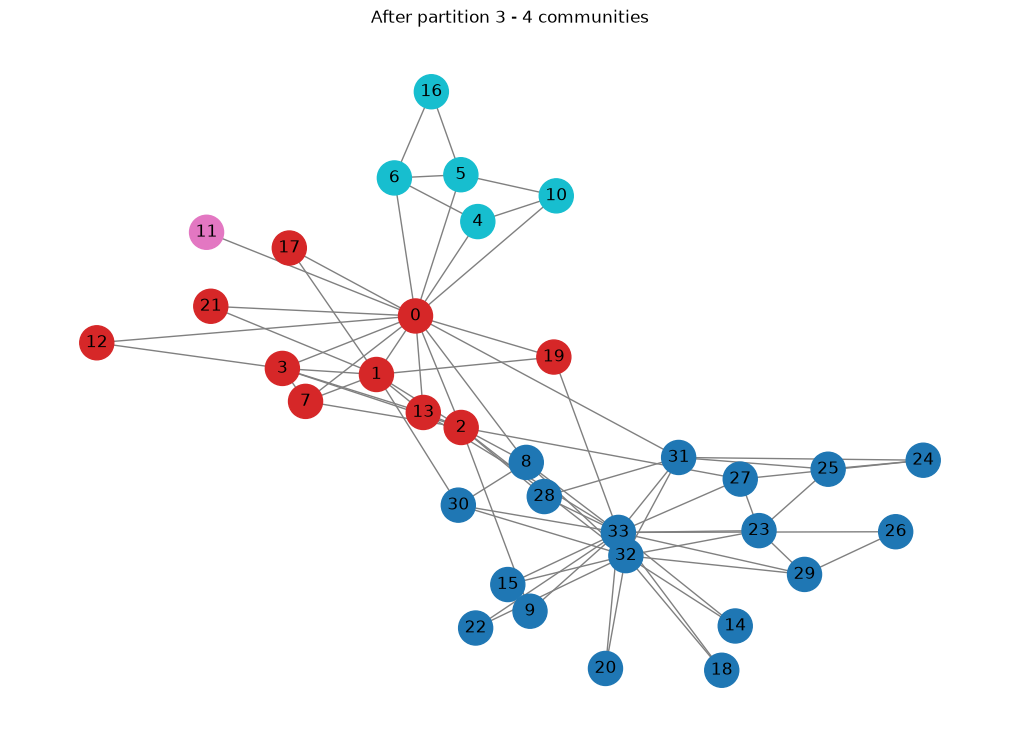

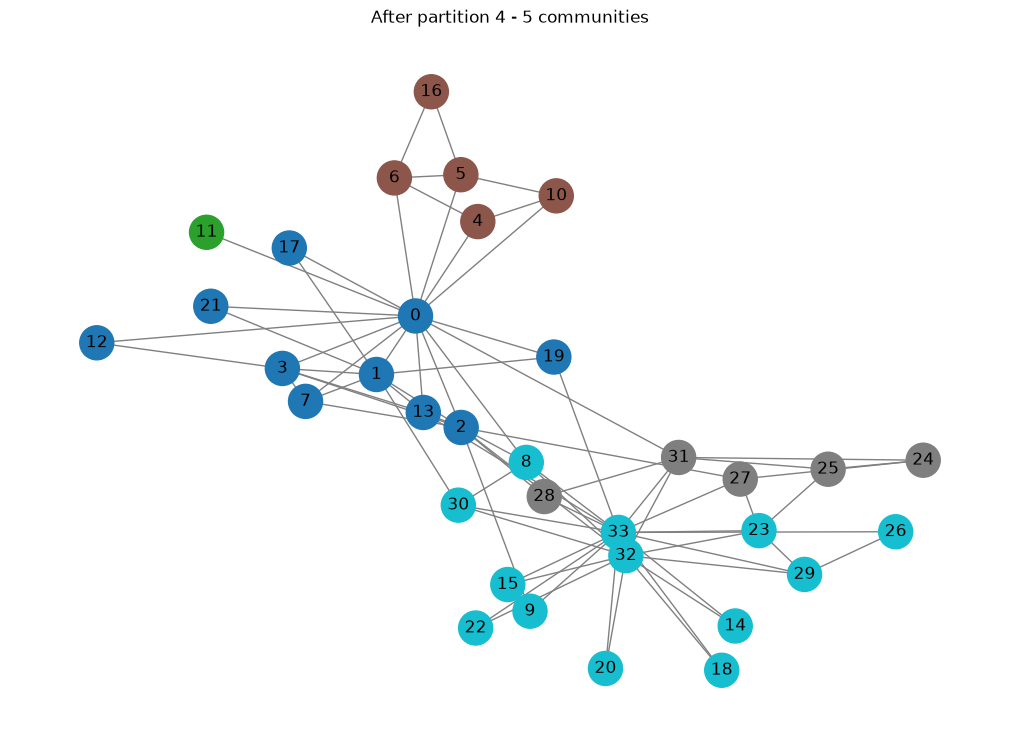

In [12]:
pos = nx.spring_layout(G, seed=42)

for i, partition in enumerate(steps):

    colors = plt.cm.tab10(np.linspace(0, 1, len(partition)))

    node_colors = {}

    for j, community in enumerate(partition):
        for node in community:
            node_colors[node] = colors[j]

    color_list = [node_colors[node] for node in G.nodes()]

    plt.figure(figsize=(10, 7))

    nx.draw(
        G, pos,
        with_labels=True,
        node_color=color_list,
        node_size=600,
        edge_color="gray"
    )

    plt.title(f"After partition {i+1} - {len(partition)} communities")
    plt.show()

After visualization of graph after partitioning and divisin into communities we move to node metrics calculation, namely;
Degree centrality,Betweenness centrality,Closeness centrality and clustering coefficient.

-Degree centrality: This measures the fraction of nodes that are cconnected to a particular vertex. Higher the degree centrality higher the hubs with connections. Its given by: Cd=Ki/n-1;
Here:
Ki= degree of vertex i
n=total nodes in the graph
Cd= degree centrality
-Betweeness centrality: This counts how often node i lies on shortest paths between other nodes. Nodes with high betweeness centrality acts as bridges, its like communication channel between nodes. Its give by: Cb= summation[(sigmai/sigma)]
where: Sigmai=Number of shortest paths between (s) and (t) that pass through vertex (i).
Sigma=Total number of shortest paths between vertices s and t.
-Closeness centrality: This measures how close a vertex is to all other vertices in the network, based on shortest-path distances.A vertex with high closeness centrality can reach other vertices through relatively short paths.
Given by:Cc=n-1/summation(d(i,j))
Where d(i,j)= shortest distance between vertex i and j;
-Clustering coefficient: Its used to determine how strongly a node's neighbours are connected to each other. Its like a measure of how likely your friends are to also be friends with one another.
Given by: C(i)=2(T(i))/ki(ki-1)
where T(i)=number of edges between its neighbours,
ki=number of neighbours of node i.
High clustering
indicates that i is embedded in a tightly-knit group



    






In [13]:
metric_history = {
    "Degree Centrality": [],
    "Betweenness Centrality": [],
    "Closeness Centrality": [],
    "Clustering Coefficient": []
}

for iteration, partition in enumerate(steps, start=1):

    degree_values = {}
    betweenness_values = {}
    closeness_values = {}
    clustering_values = {}

 # Calculating metrics separately for each community
    for community in partition:

        H = G.subgraph(community)

        dc = nx.degree_centrality(H)
        bc = nx.betweenness_centrality(H)
        cc = nx.closeness_centrality(H)
        cl = nx.clustering(H)

        degree_values.update(dc)
        betweenness_values.update(bc)
        closeness_values.update(cc)
        clustering_values.update(cl)

    metric_history["Degree Centrality"].append(degree_values)
    metric_history["Betweenness Centrality"].append(betweenness_values)
    metric_history["Closeness Centrality"].append(closeness_values)
    metric_history["Clustering Coefficient"].append(clustering_values)



In [14]:
for metric, history in metric_history.items():

    print("\n", "=" * 70)
    print(metric)
    print("=" * 70)

    for iteration, values in enumerate(history, start=1):

        print(f"\nIteration {iteration}")

        df = pd.DataFrame.from_dict(
            values,
            orient='index',
            columns=[metric]
        )

        df.index.name = "Node"

        df = df.reindex(range(G.number_of_nodes()))

        display(df.round(4))


Degree Centrality

Iteration 1


,Degree Centrality
Node,
0,0.9333
1,0.5333
2,0.3333
3,0.4000
4,0.2000
5,0.2667
6,0.2667
7,0.2667
8,0.1765



Iteration 2


,Degree Centrality
Node,
0,1.0000
1,0.8889
2,0.5556
3,0.6667
4,0.4000
5,0.6000
6,0.6000
7,0.4444
8,0.1765



Iteration 3


,Degree Centrality
Node,
0,1.0000
1,0.8889
2,0.5556
3,0.6667
4,0.5000
5,0.7500
6,0.7500
7,0.4444
8,0.1765


... (22 outputs left out)


Iteration 3


,Clustering Coefficient
Node,
0,0.3611
1,0.4286
2,0.9000
3,0.6667
4,0.0000
5,0.3333
6,0.3333
7,1.0000
8,1.0000



Iteration 4


,Clustering Coefficient
Node,
0,0.3611
1,0.4286
2,0.9000
3,0.6667
4,0.0000
5,0.3333
6,0.3333
7,1.0000
8,1.0000


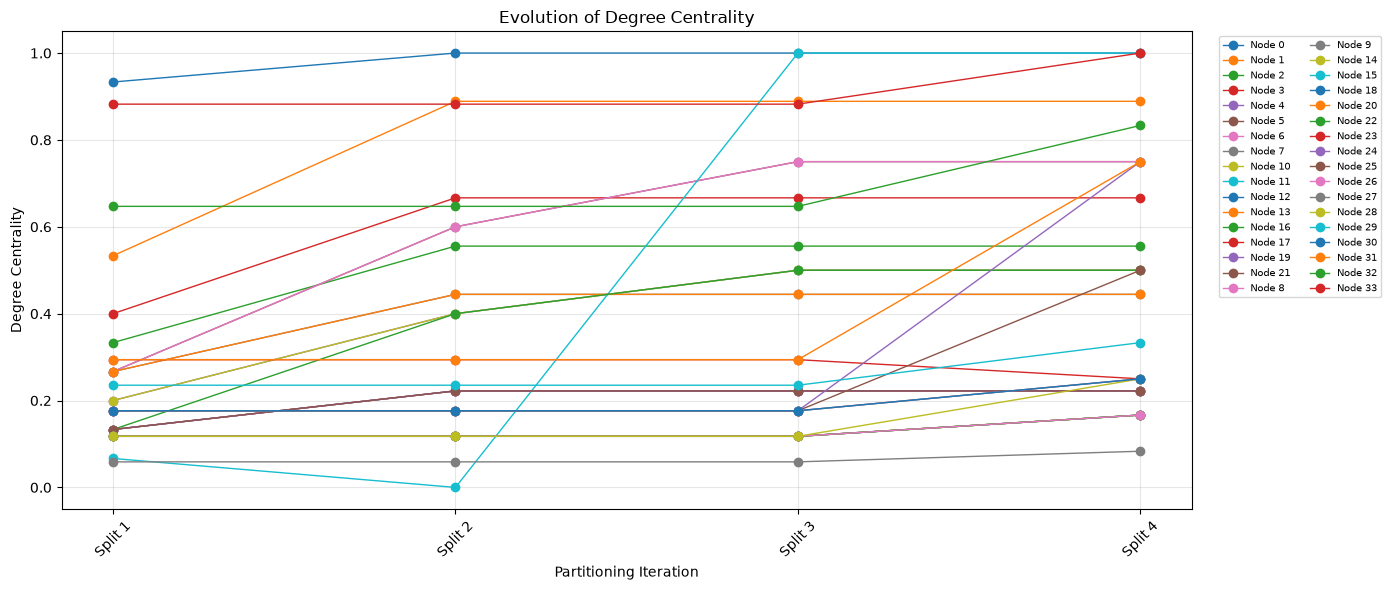

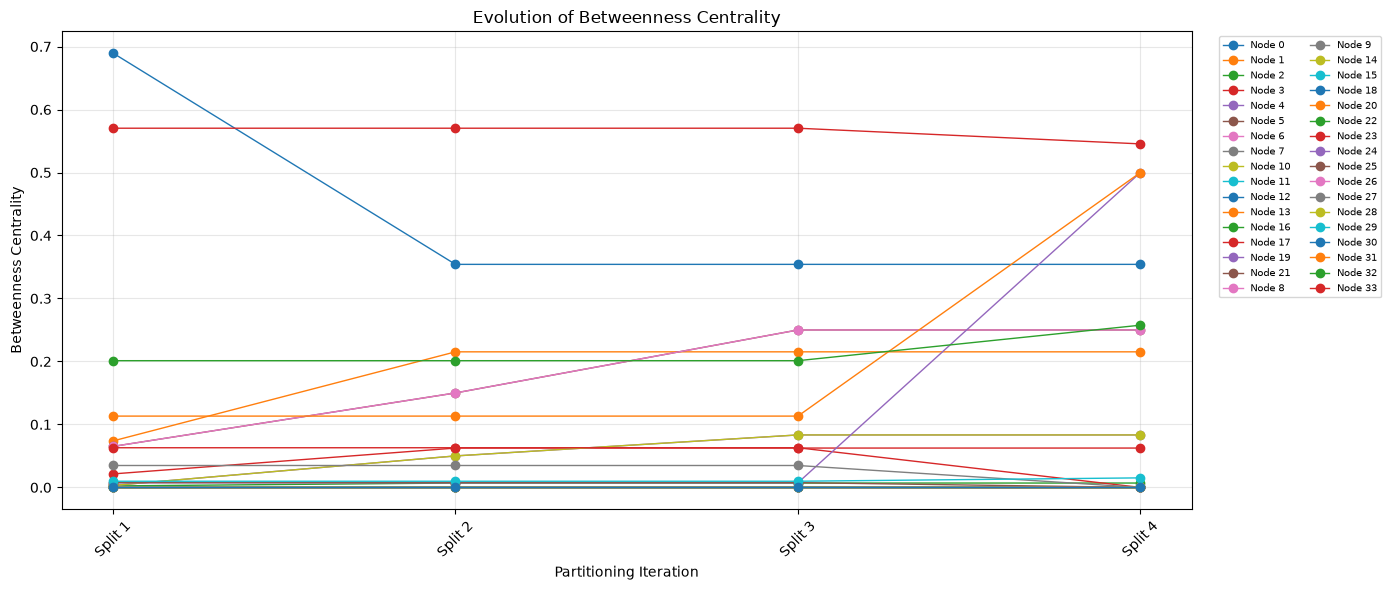

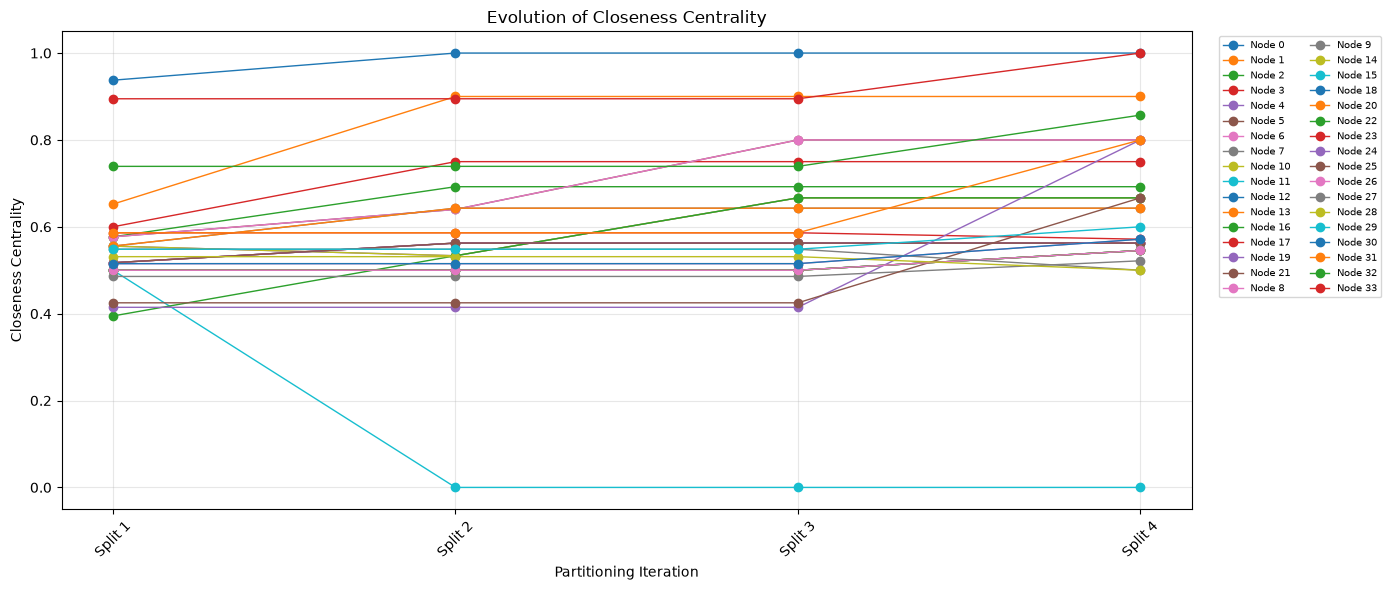

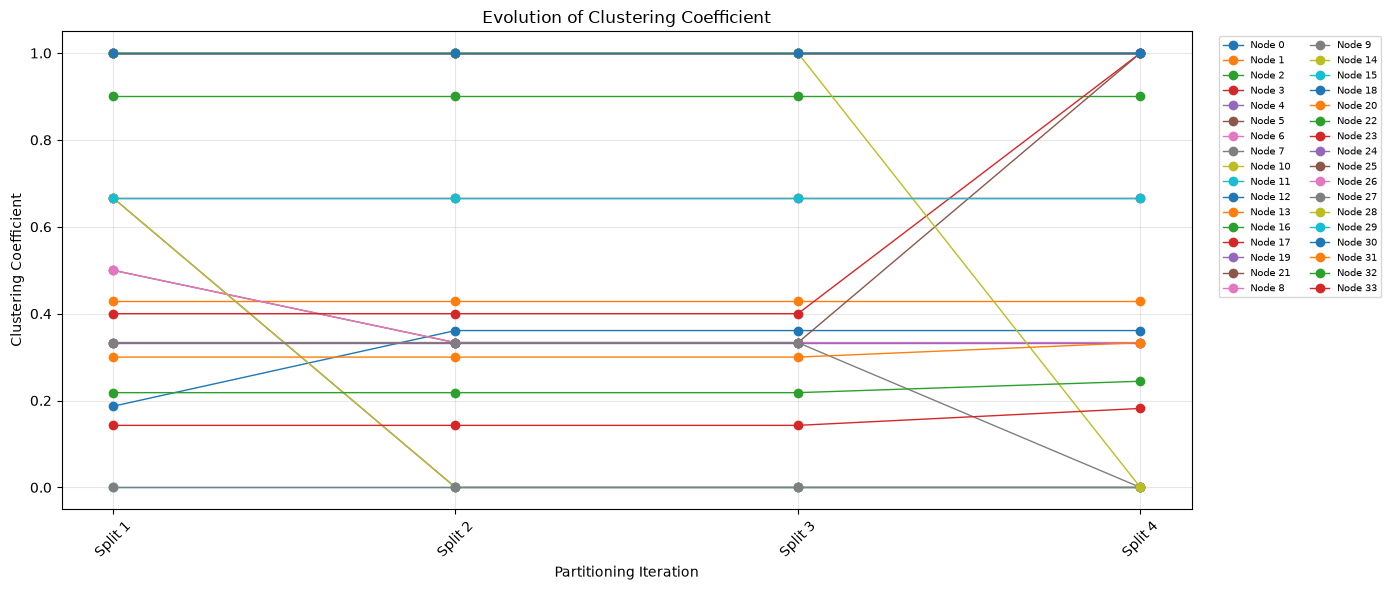

In [15]:
for metric, history in metric_history.items():

    df = pd.DataFrame(history)

    df.index = [f"Split {i+1}" for i in range(len(history))]

    plt.figure(figsize=(14, 6))

    for node in df.columns:
        plt.plot(
            df.index,
            df[node],
            marker='o',
            linewidth=1,
            label=f"Node {node}"
        )

    plt.title(f"Evolution of {metric}")
    plt.xlabel("Partitioning Iteration")
    plt.ylabel(metric)
    plt.xticks(rotation=45)
    plt.grid(alpha=0.3)

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=7,
        ncol=2
    )

    plt.tight_layout()
    plt.show()

In [16]:
for metric, history in metric_history.items():

    print("\n", metric)

    for i, values in enumerate(history, start=1):

        top_nodes = sorted(
            values.items(),
            key=lambda x: x[1],
            reverse=True
        )[:5]

        print(f"\nIteration {i}:")
        print(top_nodes)



 Degree Centrality

Iteration 1:
[(0, 0.9333333333333333), (33, 0.8823529411764706), (32, 0.6470588235294118), (1, 0.5333333333333333), (3, 0.4)]

Iteration 2:
[(0, 1.0), (1, 0.8888888888888888), (33, 0.8823529411764706), (3, 0.6666666666666666), (32, 0.6470588235294118)]

Iteration 3:
[(0, 1.0), (11, 1), (1, 0.8888888888888888), (33, 0.8823529411764706), (5, 0.75)]

Iteration 4:
[(0, 1.0), (11, 1), (33, 1.0), (1, 0.8888888888888888), (32, 0.8333333333333333)]

 Betweenness Centrality

Iteration 1:
[(0, 0.6896825396825397), (33, 0.5703431372549019), (32, 0.20122549019607844), (31, 0.11323529411764705), (1, 0.07380952380952381)]

Iteration 2:
[(33, 0.5703431372549019), (0, 0.35416666666666663), (1, 0.21527777777777776), (32, 0.20122549019607844), (5, 0.15000000000000002)]

Iteration 3:
[(33, 0.5703431372549019), (0, 0.35416666666666663), (5, 0.25), (6, 0.25), (1, 0.21527777777777776)]

Iteration 4:
[(33, 0.5454545454545454), (24, 0.5), (31, 0.5), (0, 0.35416666666666663), (32, 0.257575

 Discussion: Central Nodes and the Influence of Community Structure
 From the code above which is used to find top five nodes for each metric at every iteration, we found that
 -Node 0 consistently has very high degree and closeness centrality.
 -Node 33 consistently has high betweenness and closeness centrality.
 -Node 1 remains among the top nodes in degree, betweenness and closeness.
 -Nodes 32, 3 and 5 also appear prominently in several iterations.
 -Clustering centrality behaves differently: different nodes achieve a coefficient of 1 across iterations.
From the calculated centrality measures, nodes 0, 33 and 1 consistently emerge as important nodes throughout the recursive partitioning process.
Node 0 maintains the highest degree centrality in most iterations, reaching 1.0 in later iterations. It also consistently exhibits very high closeness centrality, indicating that it has strong connectivity and can efficiently reach other nodes within its community.
Node 33 consistently shows high betweenness centrality, with values ranging from approximately 0.55 to 0.57 in the later iterations. This suggests that it plays an important bridging role by connecting different parts of the network. Node 1 also remains among the most central nodes across the iterations, particularly in degree and closeness centrality.
Node 32 appears prominently in degree and closeness centrality, while nodes 5 and 6 become more important in betweenness centrality during later iterations. This indicates that the structural importance of nodes can change as the network is divided into smaller communities.
The clustering coefficient shows a different pattern. Several nodes, including nodes 7, 12, 13, 16, 17 and 18, achieve a clustering coefficient of 1 in different iterations. This means that all the neighbours of these nodes are interconnected within their respective communities, forming tightly connected local neighbourhoods.
 